In [47]:
import pandas as pd
import numpy as np
from pathlib import Path

# Resolve the ML directory whether Jupyter starts in the project root or in ml/.
_CWD = Path.cwd()
if (_CWD / "data" / "LSDST-2022.csv").exists() or _CWD.name == "ml":
    ML_DIR = _CWD
elif (_CWD / "ml").is_dir():
    ML_DIR = _CWD / "ml"
else:
    # When the notebook is opened from another directory, set ML_DIR to this notebook's ml folder.
    ML_DIR = _CWD

DATA_PATH = ML_DIR / "data" / "LSDST-2022.csv"
MODEL_PATH = ML_DIR / "models" / "scamlens_model.pkl"


In [2]:
df = pd.read_csv(DATA_PATH)

In [3]:
df.sample(5)

,LABEL,TEXT,URL,EMAIL,PHONE
614,ham,WHORE YOU ARE UNBELIEVABLE.,No,No,No
927,ham,Going for dinner.msg you after.,No,No,No
2605,ham,What u talking bout early morning? It's almost...,No,No,No
513,ham,Do ü all wan 2 meet up n combine all the parts...,No,No,No
5915,ham,I'm hungry buy smth home...,No,No,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5971 entries, 0 to 5970
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   LABEL   5971 non-null   object
 1   TEXT    5971 non-null   object
 2   URL     5971 non-null   object
 3   EMAIL   5971 non-null   object
 4   PHONE   5971 non-null   object
dtypes: object(5)
memory usage: 233.4+ KB


In [5]:
df.shape

(5971, 5)

### <span style="color:#6FA8DC">Phase-2 : Cleaning Data </span>

In [6]:
# cleaning data
# 1. drop unnecessary columns
# no such columns

In [7]:
# 2. rename columns for better readability
df.columns = df.columns.str.lower()

In [8]:
# 3. checking before labelencoding the unique values in our output column
print(df['label'].unique())

['ham' 'Smishing' 'spam' 'Spam' 'smishing']


In [9]:
# fixing it (3)
df['label'] = df['label'].str.lower()

In [10]:
# recheking
print(df['label'].unique())

['ham' 'smishing' 'spam']


In [11]:
# now in target column we want numerical values instead of object(string)
#  3. encode the target column
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [12]:
df['label'] = encoder.fit_transform(df['label'])
# default encoding (auto)


In [13]:
# to see encoding, 0, 1, 2 respectively 
print(encoder.classes_)

['ham' 'smishing' 'spam']


In [14]:
df.sample(5)

,label,text,url,email,phone
5733,1,\tFreeMsg Why haven't you replied to my text? ...,No,No,yes
635,2,Wan2 win a Meet+Greet with Westlife 4 U or a m...,No,No,yes
3423,0,Its ok..come to my home it vl nice to meet and...,No,No,No
1769,1,Someone U know has asked our dating service 2 ...,No,No,yes
302,0,Well there's a pattern emerging of my friends ...,No,No,No


In [15]:
# 4. check for missing values
df.isnull().sum()

label    0
text     0
url      0
email    0
phone    0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(19)

In [17]:
# since above 19 duplicate values found, lets drop them too
df.drop_duplicates(inplace=True)

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.shape

(5952, 5)

### <span style="color:#6FA8DC">Phase-3 : EDA - Exploratory Data Analysis</span>

In [20]:
# 1. lets see how many span and ham and smishing values are there respectively
# importing required libraries
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: ylabel='count'>

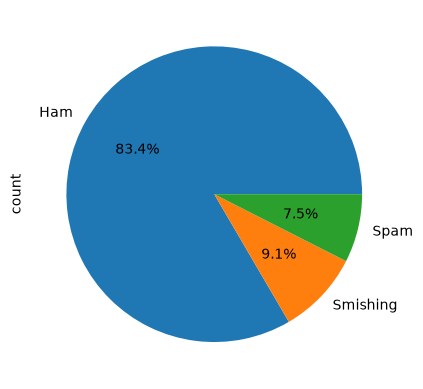

In [141]:
df['label'].value_counts().plot.pie(
    autopct='%1.1f%%',
    labels=['Ham', 'Smishing', 'Spam'],
)

In [22]:
# there what we got to know is there data inbalance, ham is too large

In [23]:

# Generate message length features before EDA
df["char_count"] = df["text"].astype(str).str.len()
df["word_count"] = df["text"].astype(str).apply(
    lambda text: len(text.split())
)

# Analyze message length by class
print(
    df.groupby("label")[["char_count", "word_count"]]
      .describe()
      .round(2)
)


      char_count                                                  word_count  \
           count    mean    std   min    25%    50%    75%    max      count   
label                                                                          
0         4834.0   70.68  56.17   2.0   34.0   53.0   91.0  910.0     4834.0   
1          629.0  139.61  32.54  34.0  127.0  146.0  156.0  383.0      629.0   
2          489.0  133.90  34.19  18.0  118.0  143.0  156.0  379.0      489.0   

                                                   
        mean    std  min   25%   50%   75%    max  
label                                              
0      14.16  11.10  1.0   7.0  11.0  19.0  171.0  
1      22.81   5.91  5.0  20.0  23.0  27.0   68.0  
2      23.00   6.59  2.0  20.0  24.0  27.0   61.0  


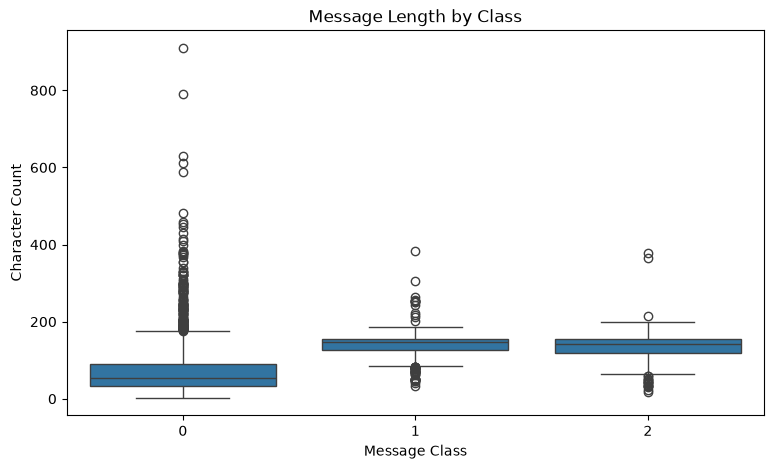

In [24]:


plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="label", y="char_count")

plt.title("Message Length by Class")
plt.xlabel("Message Class")
plt.ylabel("Character Count")

plt.show()

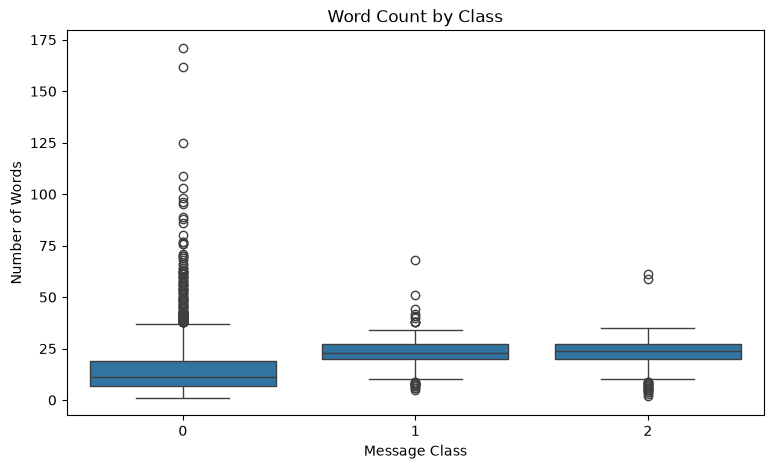

In [25]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="label", y="word_count")

plt.title("Word Count by Class")
plt.xlabel("Message Class")
plt.ylabel("Number of Words")

plt.show()

In [26]:
import pandas as pd

binary_cols = ["url", "email", "phone"]

for col in binary_cols:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    print(f"\nPercentage distribution for {col}:")

    print(
        pd.crosstab(
            df["label"],
            df[col],
            normalize="index"
        ).mul(100).round(2)
    )


Percentage distribution for url:
url       no    yes
label              
0      99.83   0.17
1      84.10  15.90
2      79.75  20.25

Percentage distribution for email:
email     no   yes
label             
0      99.98  0.02
1      98.25  1.75
2      98.57  1.43

Percentage distribution for phone:
phone     no    yes
label              
0      99.86   0.14
1      17.65  82.35
2      36.61  63.39




#### <span style="color:#F3C6D3">to have more better understanding of data : lets get more columns like no of words , chars and all then again doing EDA on it to analyse it more. </br> </br> Therefore, moving into the Feature Engineering / Feature Extraction
</span>

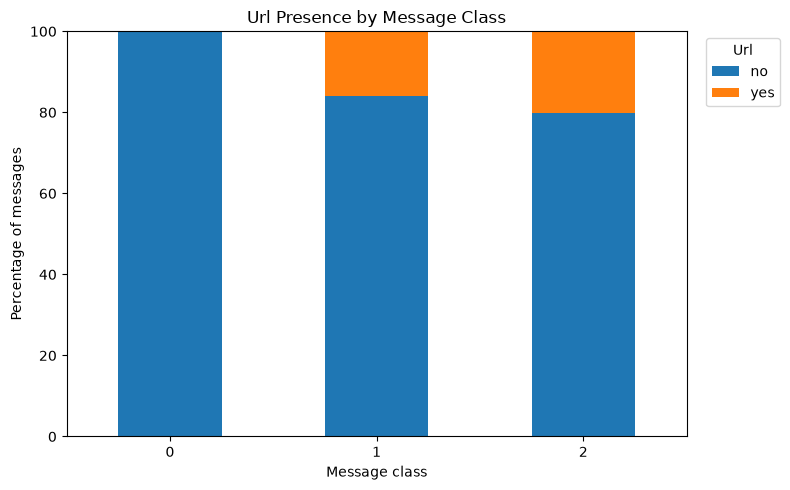

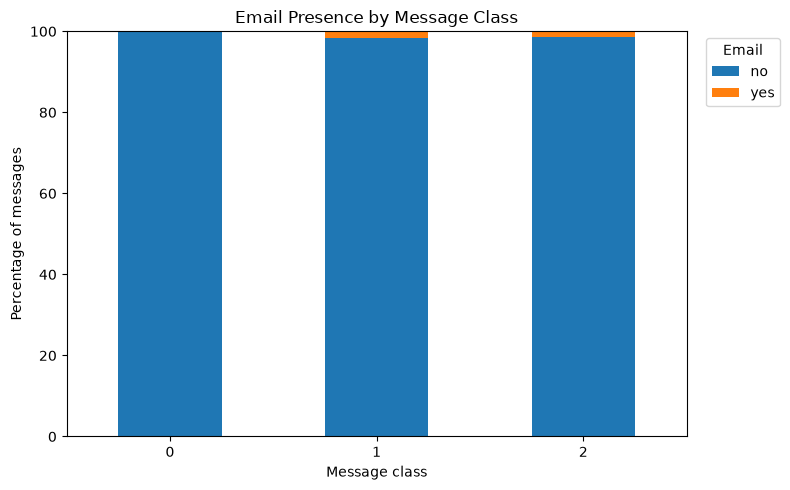

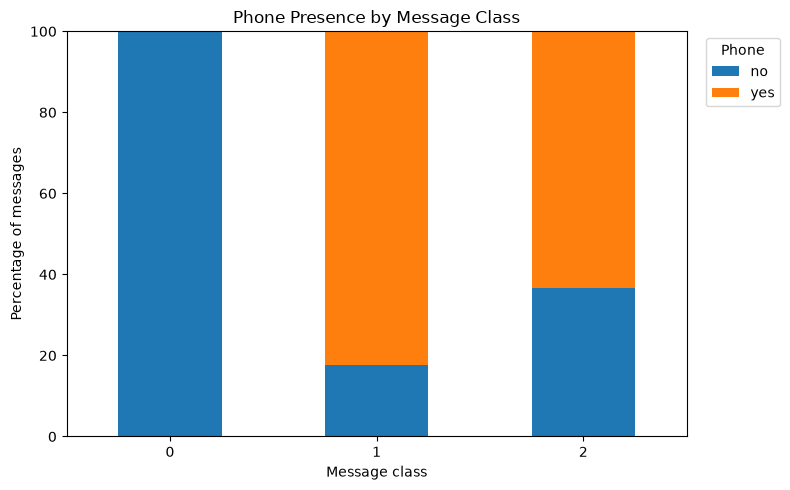

In [27]:
binary_cols = ["url", "email", "phone"]

# Normalize Yes/No values
for col in binary_cols:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# Percentage of Yes/No within each class
for col in binary_cols:
    table = pd.crosstab(
        df["label"],
        df[col],
        normalize="index"
    ).mul(100)

    # Ensure both categories exist
    table = table.reindex(columns=["no", "yes"], fill_value=0)

    ax = table.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5),
        ylabel="Percentage of messages",
        xlabel="Message class",
        title=f"{col.title()} Presence by Message Class",
        ylim=(0, 100),
        rot=0
    )

    ax.legend(title=col.title(), bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

In [28]:
print(df.columns.tolist())
print(df.columns[df.columns.duplicated()])

['label', 'text', 'url', 'email', 'phone', 'char_count', 'word_count']
Index([], dtype='object')


In [29]:
df = df.loc[:, ~df.columns.duplicated()]

In [30]:
df.sample(5)

,label,text,url,email,phone,char_count,word_count
2462,0,Hey what happen de. Are you alright.,no,no,no,36,7
4469,0,I love u 2 my little pocy bell I am sorry but ...,no,no,no,54,15
386,0,"Yep, by the pretty sculpture",no,no,no,28,5
5944,0,Tmr timin still da same wat cos i got lesson u...,no,no,no,55,12
2080,0,"Wow ... I love you sooo much, you know ? I can...",no,no,no,152,37


In [31]:
# Feature Engineering / Feature Extraction

In [32]:
import re

In [33]:

def extract_features(text):
    text = str(text)
    words = text.split()

    features = {
        "char_count": len(text),
        "word_count": len(words),
        "digit_count": sum(c.isdigit() for c in text),
        "uppercase_count": sum(c.isupper() for c in text),
        "special_char_count": sum(
            not c.isalnum() and not c.isspace() for c in text
        ),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),

        "url_count": len(re.findall(
            r'https?://\S+|www\.\S+',
            text,
            flags=re.IGNORECASE
        )),

        "has_url": int(bool(re.search(
            r'https?://\S+|www\.\S+',
            text,
            flags=re.IGNORECASE
        ))),

        "has_email": int(bool(re.search(
            r'[\w\.-]+@[\w\.-]+\.\w+',
            text
        ))),

        "has_phone": int(bool(re.search(
            r'\b(?:\+?\d[\d\s-]{8,}\d)\b',
            text
        ))),

        "has_money_symbol": int(
            any(symbol in text for symbol in ["₹", "$", "€", "£"])
        ),

        "urgent_word_count": sum(
            word.lower() in {
                "urgent", "immediately", "now", "hurry",
                "alert", "important", "expires"
            }
            for word in words
        ),

        "reward_word_count": sum(
            word.lower() in {
                "win", "winner", "won", "prize",
                "reward", "gift", "bonus"
            }
            for word in words
        ),

        "claim_word_count": sum(
            word.lower() in {
                "claim", "redeem", "collect", "receive"
            }
            for word in words
        )
    }

    return pd.Series(features)

In [137]:
df["url"] = df["url"].map({"yes": 1, "no": 0}).fillna(0).astype(int)
df["email"] = df["email"].map({"yes": 1, "no": 0}).fillna(0).astype(int)
df["phone"] = df["phone"].map({"yes": 1, "no": 0}).fillna(0).astype(int)

In [140]:
print(f"\n{col} value counts:")
print(df[col].value_counts(dropna=False))


word_count value counts:
word_count
6      420
7      388
8      349
5      348
9      319
      ... 
71       1
55       1
171      1
109      1
162      1
Name: count, Length: 83, dtype: int64


In [138]:
features = df["text"].apply(extract_features)

In [36]:
# combine/merge with orginal dataframe

# Feature Engineering / Feature Extraction

# Remove existing versions of the generated features
df = df.drop(
    columns=df.columns.intersection(features.columns),
    errors="ignore"
)

# Add the features only once
df = pd.concat([df, features], axis=1)

# Verify
print("Duplicate columns:", df.columns[df.columns.duplicated()].tolist())
print("Data shape:", df.shape)

assert df.columns.is_unique, "Duplicate columns detected!"



Duplicate columns: []
Data shape: (5952, 20)


In [37]:
df.sample(5)

,label,text,url,email,phone,char_count,word_count,digit_count,uppercase_count,special_char_count,exclamation_count,question_count,url_count,has_url,has_email,has_phone,has_money_symbol,urgent_word_count,reward_word_count,claim_word_count
178,0,Living is very simple.. Loving is also simple....,0,0,0,145,23,0,12,20,0,0,0,0,0,0,0,0,0,0
2589,0,The problem I have felt is you have the time ...,0,0,0,78,18,0,2,2,0,0,0,0,0,0,0,0,0,0
841,0,Smith waste da.i wanna gayle.,0,0,0,29,5,0,1,2,0,0,0,0,0,0,0,0,0,0
3179,1,\tReminder: You have not downloaded the conten...,0,0,0,128,20,0,3,9,0,0,1,1,0,0,0,0,0,1
316,0,Sorry for the delay. Yes masters,0,0,0,32,6,0,2,1,0,0,0,0,0,0,0,0,0,0


In [38]:
# lets visualize it too

# Count 0 and 1 in every column
zero_counts = (df == 0).sum()
one_counts = (df == 1).sum()

print("Zeros:\n", zero_counts)
print("\nOnes:\n", one_counts)

Zeros:
 label                 4834
text                     0
url                   5952
email                 5952
phone                 5952
char_count               0
word_count               0
digit_count           4133
uppercase_count         86
special_char_count     454
exclamation_count     4942
question_count        4676
url_count             5769
has_url               5769
has_email             5929
has_phone             5271
has_money_symbol      5645
urgent_word_count     5597
reward_word_count     5700
claim_word_count      5738
dtype: int64

Ones:
 label                  629
text                     0
url                      0
email                    0
phone                    0
char_count               0
word_count              21
digit_count            490
uppercase_count       1898
special_char_count     911
exclamation_count      675
question_count        1068
url_count              182
has_url                183
has_email               23
has_phone              681

label                   0       1       2
char_count          70.68  139.61  133.90
word_count          14.16   22.81   23.00
digit_count          0.32   16.90   12.58
uppercase_count      3.92   14.87   15.42
special_char_count   3.88    5.90    6.30
exclamation_count    0.18    0.62    0.55
question_count       0.29    0.16    0.27
url_count            0.00    0.15    0.18
urgent_word_count    0.04    0.21    0.14
reward_word_count    0.00    0.37    0.13
claim_word_count     0.00    0.37    0.04


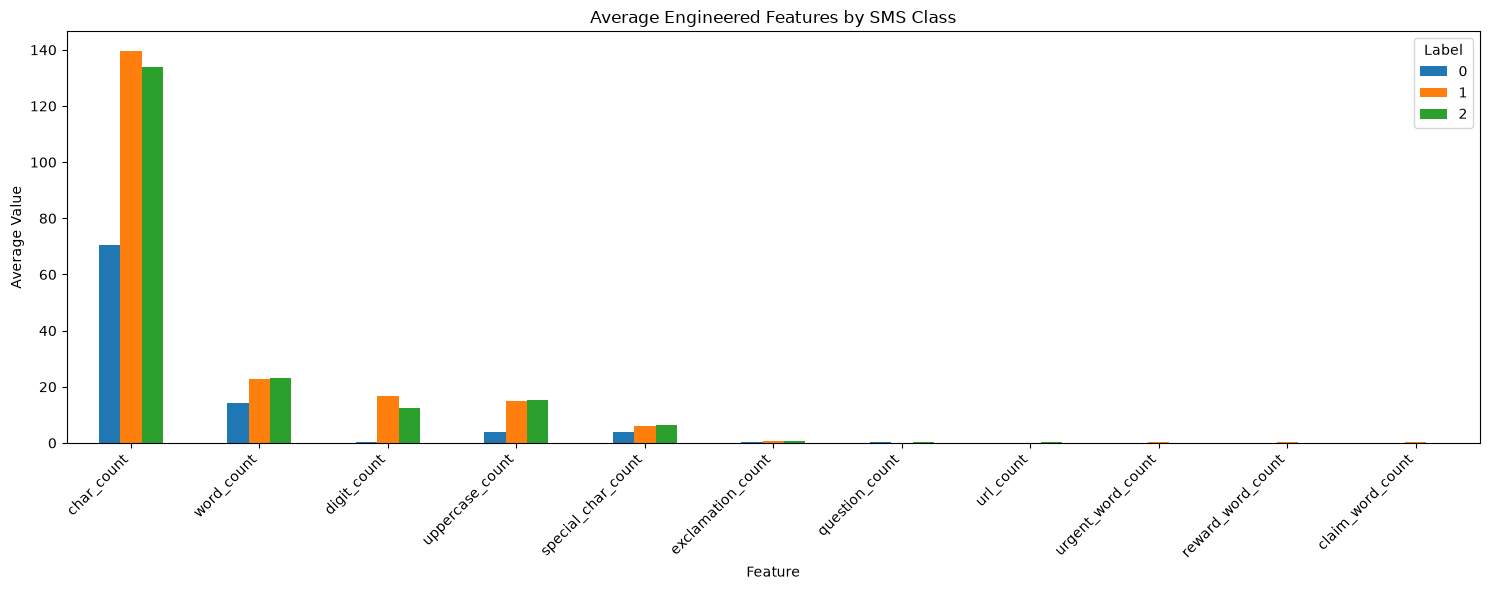

In [39]:
features = [
    "char_count",
    "word_count",
    "digit_count",
    "uppercase_count",
    "special_char_count",
    "exclamation_count",
    "question_count",
    "url_count",
    "urgent_word_count",
    "reward_word_count",
    "claim_word_count"
]

feature_means = df.groupby("label")[features].mean().T

feature_means.plot(
    kind="bar",
    figsize=(15, 6)
)

print(
    df.groupby("label")[features]
      .mean()
      .round(2)
      .T
)

plt.title("Average Engineered Features by SMS Class")
plt.xlabel("Feature")
plt.ylabel("Average Value")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Label")
plt.tight_layout()
plt.show()

In [40]:
print(encoder.classes_)

['ham' 'smishing' 'spam']


#### <span style=color:#7FB3D5>next target is to lets observe the data mathematcially using describe function </span>

In [41]:
important_features = [
    "char_count",
    "word_count",
    "digit_count",
    "uppercase_count",
    "special_char_count",
    "url_count",
    "urgent_word_count",
    "reward_word_count",
    "claim_word_count"
]

# Summary for each class
for label in sorted(df["label"].unique()):
    print(f"\n{'=' * 20} LABEL {label} {'=' * 20}")
    display(
        df.loc[df["label"] == label, important_features].describe().T
    )


==================== LABEL 0 ====================


,count,mean,std,min,25%,50%,75%,max
char_count,4834.0,70.677079,56.169202,2.0,34.0,53.0,91.0,910.0
word_count,4834.0,14.160943,11.103232,1.0,7.0,11.0,19.0,171.0
digit_count,4834.0,0.317749,1.129513,0.0,0.0,0.0,0.0,23.0
uppercase_count,4834.0,3.923252,10.204900,0.0,1.0,2.0,3.0,129.0
special_char_count,4834.0,3.875259,4.400679,0.0,1.0,3.0,5.0,133.0
url_count,4834.0,0.000414,0.020338,0.0,0.0,0.0,0.0,1.0
urgent_word_count,4834.0,0.037236,0.192610,0.0,0.0,0.0,0.0,2.0
reward_word_count,4834.0,0.002896,0.060959,0.0,0.0,0.0,0.0,2.0
claim_word_count,4834.0,0.001862,0.043113,0.0,0.0,0.0,0.0,1.0



==================== LABEL 1 ====================


,count,mean,std,min,25%,50%,75%,max
char_count,629.0,139.612083,32.540601,34.0,127.0,146.0,156.0,383.0
word_count,629.0,22.813990,5.907358,5.0,20.0,23.0,27.0,68.0
digit_count,629.0,16.901431,8.284731,0.0,12.0,17.0,22.0,47.0
uppercase_count,629.0,14.872814,14.111466,0.0,6.0,12.0,21.0,128.0
special_char_count,629.0,5.895072,3.588968,0.0,3.0,5.0,8.0,26.0
url_count,629.0,0.152623,0.359910,0.0,0.0,0.0,0.0,1.0
urgent_word_count,629.0,0.205087,0.476425,0.0,0.0,0.0,0.0,3.0
reward_word_count,629.0,0.372019,0.666471,0.0,0.0,0.0,1.0,3.0
claim_word_count,629.0,0.368839,0.651345,0.0,0.0,0.0,1.0,4.0



==================== LABEL 2 ====================


,count,mean,std,min,25%,50%,75%,max
char_count,489.0,133.897751,34.189889,18.0,118.0,143.0,156.0,379.0
word_count,489.0,23.002045,6.591257,2.0,20.0,24.0,27.0,61.0
digit_count,489.0,12.578732,8.075365,0.0,5.0,13.0,19.0,35.0
uppercase_count,489.0,15.419223,12.522035,0.0,7.0,13.0,20.0,104.0
special_char_count,489.0,6.304703,3.888718,0.0,3.0,6.0,8.0,26.0
url_count,489.0,0.175869,0.386438,0.0,0.0,0.0,0.0,2.0
urgent_word_count,489.0,0.141104,0.354317,0.0,0.0,0.0,0.0,2.0
reward_word_count,489.0,0.134969,0.365220,0.0,0.0,0.0,0.0,2.0
claim_word_count,489.0,0.042945,0.202940,0.0,0.0,0.0,0.0,1.0


In [42]:
binary_features = [
    "has_url",
    "has_email",
    "has_phone",
    "has_money_symbol"
]

# Percentage of messages in each class containing each indicator
binary_comparison = (
    df.groupby("label")[binary_features]
      .mean()
      .mul(100)
      .round(2)
)

display(binary_comparison)

,has_url,has_email,has_phone,has_money_symbol
label,,,,
0,0.04,0.02,0.08,0.37
1,15.26,2.07,77.27,30.37
2,17.38,1.84,39.06,20.04


#### EDA Findings

1. **Class imbalance:** Ham messages dominate the dataset, accounting for approximately 81% of all samples. Smishing and Spam represent much smaller classes, so evaluation should include per-class precision, recall, and F1-score rather than accuracy alone.

2. **Message length:** Ham messages are shorter on average than Smishing and Spam messages. Character count and word count may help distinguish legitimate messages from suspicious ones, but they provide limited separation between Smishing and Spam.

3. **Numeric and formatting features:** Smishing and Spam contain substantially more digits and uppercase characters than Ham. These features may provide useful classification signals, although their distributions can overlap.

4. **Suspicious-language features:** Reward-related and claim-related terms occur more frequently in Smishing than in Ham or Spam in this dataset. Urgency-related terms also occur more frequently in the suspicious classes.

5. **Binary indicators:** URL, phone, and money-symbol indicators show noticeable differences between classes. The phone indicator is especially prominent in Smishing. Email presence is rare across all classes.

6. **Outliers:** Some messages have unusually high character counts, word counts, or digit counts. These observations should be investigated rather than removed automatically.

7. **Overall conclusion:** The engineered numerical features reveal useful differences, particularly between Ham and the suspicious classes. However, Smishing and Spam share several characteristics. ScamLens should therefore combine engineered features with text-based features, such as TF-IDF, and evaluate their contribution through model testing.

In [43]:
for col in ["char_count", "word_count"]:
    copies = df.loc[:, df.columns == col]
    print(col, "copies identical:", copies.nunique(axis=1).max() == 1)

char_count copies identical: True
word_count copies identical: True


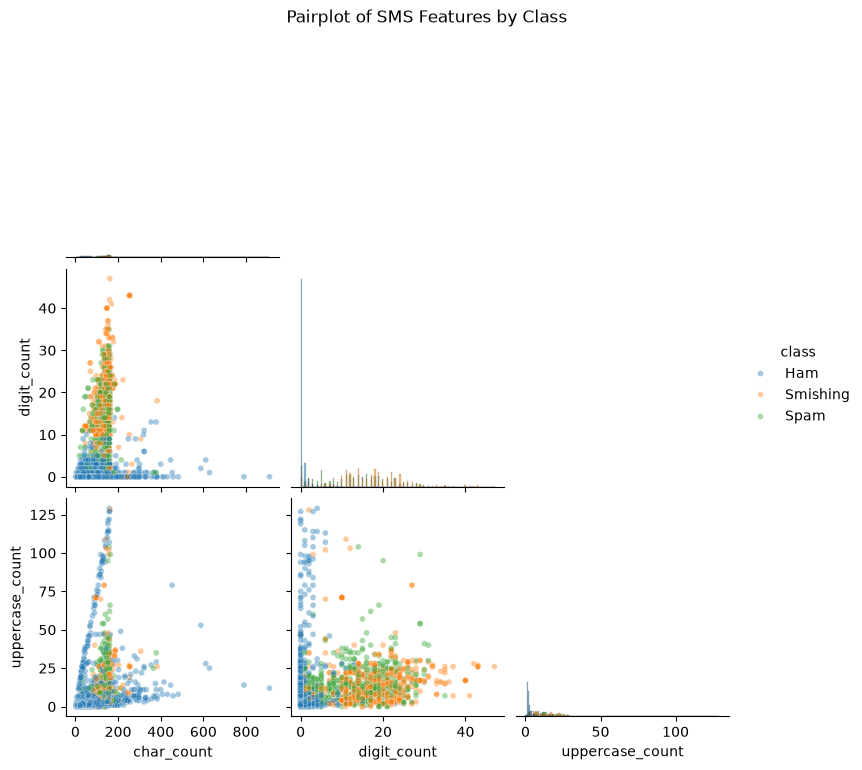

In [45]:
# using pairplot of seaborn to see relations


plot_features = ["char_count", "digit_count", "uppercase_count"]

plot_df = df[plot_features + ["label"]].copy()
plot_df["class"] = plot_df["label"].map({0: "Ham", 1: "Smishing", 2: "Spam"})

sns.pairplot(
    plot_df.drop(columns="label"),
    hue="class",
    hue_order=["Ham", "Smishing", "Spam"],
    diag_kind="hist",
    diag_kws={"stat": "density", "common_norm": False},
    corner=True,
    plot_kws={"alpha": 0.4, "s": 18},
)
plt.suptitle("Pairplot of SMS Features by Class", y=1.02)
plt.show()


#### Feature Analysis

- **Digit Count:** Ham and suspicious messages are well separated by digit count. About 84% of Ham messages contain zero digits, compared with 3.5% of Smishing and 8.4% of Spam messages. `digit_count` is the strongest numeric feature identified so far.

- **Message Length:** Length is useful only in combination with other features. Suspicious messages cluster around 100–200 characters, while Ham messages range from very short to approximately 900 characters. Short messages are mostly Ham, but many Ham messages also fall within the 100–200 character range.

- **Uppercase Count:** Uppercase count is useful mainly when combined with digit count. Some legitimate Ham messages are written entirely in capital letters, so relying on uppercase count alone may lead to misclassification.

- **Smishing vs. Spam:** Smishing and Spam overlap significantly across all the plotted features, making them difficult to distinguish using these numeric features alone.

<h3 style="color: #F8C8DC;">Next - Heatmap</h3>

### Why a Heatmap?

A heatmap shows correlations between features and helps identify which features carry similar information.

**Why it matters for ScamLens:**
- **Identify redundancy:** Highly correlated features may provide overlapping information, potentially affecting model stability and interpretability. Logistic Regression coefficients can become unstable, while Naive Bayes may double-count similar evidence.
- **Feature selection:** Helps identify features that could be removed or combined, such as `char_count` and `word_count`.
- **Understand feature overlap:** Reveals relationships among handcrafted features and helps assess potential redundancy with TF-IDF features later.

**Limitations:**
- **Does not measure classification usefulness:** A highly correlated feature may still be useful, while an uncorrelated feature may have little predictive value.
- **Ignores class labels:** A heatmap cannot determine whether features distinguish Ham, Smishing, and Spam.
- **Misses complex relationships:** Correlation measures specific types of association and may fail to capture nonlinear relationships.

Duplicate column names: False


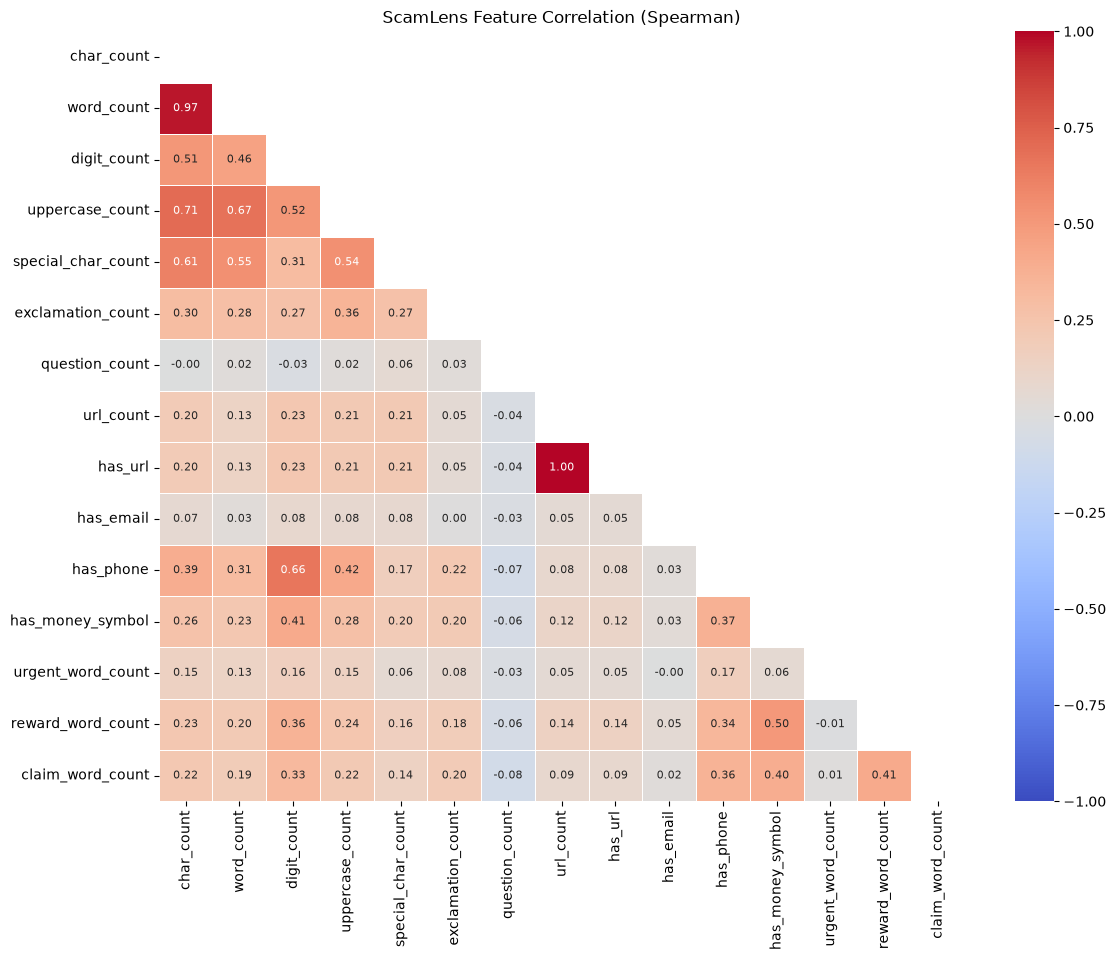

         feature_1       feature_2     corr  abs_corr
           has_url       url_count 0.999997  0.999997
        word_count      char_count 0.965621  0.965621
   uppercase_count      char_count 0.706934  0.706934
   uppercase_count      word_count 0.672227  0.672227
         has_phone     digit_count 0.660026  0.660026
special_char_count      char_count 0.610773  0.610773
special_char_count      word_count 0.546151  0.546151
special_char_count uppercase_count 0.540108  0.540108
   uppercase_count     digit_count 0.515344  0.515344
       digit_count      char_count 0.510032  0.510032


In [48]:
# Now going into heatmap

# Safety check: the earlier duplicate-column problem
print("Duplicate column names:", df.columns.duplicated().any())

heatmap_features = [
    "char_count", "word_count", "digit_count", "uppercase_count",
    "special_char_count", "exclamation_count", "question_count",
    "url_count", "has_url", "has_email", "has_phone", "has_money_symbol",
    "urgent_word_count", "reward_word_count", "claim_word_count",
]

corr = df[heatmap_features].astype(float).corr(method="spearman")

# Hide the redundant upper triangle (the matrix is symmetric)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5,
)
plt.title("ScamLens Feature Correlation (Spearman)")
plt.show()

# The numbers we actually care about: the most correlated pairs
pairs = (
    corr.where(~mask).stack()
        .rename("corr").reset_index()
        .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)
pairs["abs_corr"] = pairs["corr"].abs()
print(pairs.sort_values("abs_corr", ascending=False).head(10).to_string(index=False))

</br>
</br>

#### How I Read It

I go through a correlation heatmap in a fixed order, so I don't just chase the loudest colour:

1. **Sanity check.** The matrix is lower-triangular and the strongest cell is exactly 1.00, so the setup worked. There is no duplicate-column artifact.
2. **Find the extremes first** (|r| above about 0.8), because those are potential redundancies.
3. **Find blocks** of moderate correlation (0.4–0.7), because those are feature families.
4. **Find near-zero rows,** because those features either carry independent information or are too sparse to correlate meaningfully with anything.
5. **Score my own predictions** against the results.
6. **Ask what could mislead me.** This matters most because correlation alone does not establish predictive usefulness or causation.

### Observations (What the Figure Shows)

**1. Two near-duplicates.**

- `char_count` and `word_count`: **0.97**.
- `url_count` and `has_url`: **1.00**.

**2. A "message size" family.**

- `char_count` correlates with `uppercase_count` at **0.71**, `special_char_count` at **0.61**, and `digit_count` at **0.51**.
- `word_count` follows the same pattern, with

### <span style="color:#7FB3D5">Multicollinearity Observation</span>


A very high correlation (0.97) is observed between the number of characters and the number of words, indicating that these features contain highly similar information. This potential redundancy will be considered during feature selection and model evaluation. If necessary, we can choose one of these features instead of using both.

A perfect correlation (1.00) is observed between `url_count` and `has_url`. This suggests that most messages contain at most one URL, so the count adds little beyond the presence indicator. This will be confirmed by checking the value counts of `url_count`, and one of the two features may be sufficient.

Moderate correlations (0.51 to 0.71) are observed between message length and the digit, uppercase and special-character counts. This is expected, since longer messages naturally contain more characters of every kind. These raw counts therefore partly reflect message length, and ratio-based features could be considered later if needed.

**Limitations:** These correlations were calculated across all classes combined, so some may partly reflect differences between classes rather than direct relationships between features. The heatmap also does not show which features separate Ham, Smishing and Spam. No features are removed at this stage, and the final feature set will be decided during model preparation and evaluation.

### <span style="color:#7FB3D5">Phase-3.2: Feature Selection after analysis</span>


In [49]:
print(df["url_count"].value_counts())

url_count
0    5769
1     182
2       1
Name: count, dtype: int64


In [50]:
# going safe and thus only dropping url_count
# that’s a safe drop. url_count is fully covered by has_url, and nothing else is derived from
df = df.drop(columns=["url_count"], errors="ignore")

print("url_count" in df.columns)   # should print False
print(df.shape)

False
(5952, 19)


In [51]:
df.sample(5)

,label,text,url,email,phone,char_count,word_count,digit_count,uppercase_count,special_char_count,exclamation_count,question_count,has_url,has_email,has_phone,has_money_symbol,urgent_word_count,reward_word_count,claim_word_count
1997,0,Thanks for sending this mental ability question..,0,0,0,49,7,0,1,2,0,0,0,0,0,0,0,0,0
1660,1,Dear (paytm)customer your paytm KYC has been s...,0,0,0,131,21,12,16,5,0,0,0,0,1,0,0,0,0
2851,0,"Ok thats cool. Its , just off either raglan rd...",0,0,0,131,25,0,4,5,0,0,0,0,0,0,0,0,0
929,2,\tFree Top ringtone -sub to weekly ringtone-ge...,0,0,0,115,16,18,9,7,0,1,0,0,1,0,0,0,0
4680,0,As in i want custom officer discount oh.,0,0,0,40,8,0,1,1,0,0,0,0,0,0,0,0,0


In [52]:
import re
import numpy as np
import pandas as pd

df = df.copy()
df["text"] = df["text"].astype(str).str.strip()          # removes leading \t, spaces
print(df[["text", "label"]].isna().sum())

# near-duplicate key: lowercase, letters/digits only
df["dup_key"] = df["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)

# check for conflicting labels first
conflicts = df.groupby("dup_key")["label"].nunique()
print("Same text, different labels:", (conflicts > 1).sum())

df = df.drop_duplicates(subset="dup_key", keep="first").drop(columns="dup_key")
print(df.shape, df["label"].value_counts())

text     0
label    0
dtype: int64
Same text, different labels: 35
(5824, 19) label
0    4829
1     543
2     452
Name: count, dtype: int64


In [53]:
df["dup_key"] = df["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)

nun = df.groupby("dup_key")["label"].nunique()
conf_keys = nun[nun > 1].index

conf = df[df["dup_key"].isin(conf_keys)].sort_values("dup_key")

# which label pairs are clashing?
pairs = conf.groupby("dup_key")["label"].apply(lambda s: tuple(sorted(s.unique())))
print(pairs.value_counts())

# eyeball them
pd.set_option("display.max_colwidth", 120)
print(conf[["label", "text"]].head(30))

Series([], Name: count, dtype: int64)
Empty DataFrame
Columns: [label, text]
Index: []


In [54]:
raw = pd.read_csv(DATA_PATH)      # your original file
print(raw.columns.tolist())

TEXT_COL = "TEXT"                       # <- set to your real text column name

chk = pd.DataFrame({
    "text":  raw[TEXT_COL].astype(str).str.strip(),
    "label": raw["LABEL"].str.strip().str.lower().map({"ham": 0, "smishing": 1, "spam": 2}),
})
chk["dup_key"] = chk["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)

nun = chk.groupby("dup_key")["label"].nunique()
conf_keys = nun[nun > 1].index
conf = chk[chk["dup_key"].isin(conf_keys)].sort_values("dup_key")

pairs = conf.groupby("dup_key")["label"].apply(lambda s: tuple(sorted(s.unique())))
print(pairs.value_counts())

pd.set_option("display.max_colwidth", 120)
print(conf[["label", "text"]].head(30))

['LABEL', 'TEXT', 'URL', 'EMAIL', 'PHONE']
label
(1, 2)    35
Name: count, dtype: int64
      label  \
67        2   
1406      1   
3579      2   
4446      1   
3352      2   
2704      1   
1087      1   
4137      2   
4127      2   
1434      1   
1629      1   
2789      2   
1985      1   
3006      2   
4243      2   
4910      1   
3652      1   
1081      2   
321       1   
254       2   
905       1   
3813      2   
1297      1   
4411      2   
3060      2   
4499      1   
213       1   
1213      2   
2429      2   
5676      1   

                                                                                                                         text  
67    5 Free Top Polyphonic Tones call 087018728737, National Rate. Get a toppoly tune sent every week, just text SUBPOLY ...  
1406  5 Free Top Polyphonic Tones call 087018728737, National Rate. Get a toppoly tune sent every week, just text SUBPOLY ...  
3579  Bears Pic Nick, and Tom, Pete and ... Dick. In fact, all

In [55]:
df["dup_key"] = df["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
df = df[~df["dup_key"].isin(set(conf_keys))].drop(columns="dup_key")
print(df.shape)
print(df["label"].value_counts())

(5789, 19)
label
0    4829
1     527
2     433
Name: count, dtype: int64


In [56]:
print("dup_key" in df.columns)   # should print False

False


### <span style="color:#7FB3D5">Phase-4: Data Preprocessing</span>

1. **Lowercasing** - Convert all text to lowercase for consistency.
2. **Tokenization** - Split the text into individual words (tokens).
3. **Removing Special Characters** - Remove unnecessary symbols and special characters.
4. **Removing Stop Words and Punctuation** - Remove common words and punctuation that provide little useful information.
5. **Stemming** - Reduce words to their root/base form.    Example: `playing`, `played`, `plays` → `play`

In [57]:
# Import stopwords
import re, nltk
from nltk.corpus import stopwords

# Download stopwords dataset
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab") 

# to see English stopwords
# stopwords.words('english')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\devma\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\devma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\devma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [58]:
# now for stemmer
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
# ps.stem("dancing")
# ps.stem("loving")


In [59]:
# build the stopword set once, and keep words that matter for spam
keep = {"now", "free", "not", "no", "you", "your", "to", "call", "stop"}
stop_words = set(stopwords.words("english")) - keep

def transform_text(text):
    text = text.lower()

    # NEW: replace urls, money, phone numbers and numbers with tokens
    # (must happen BEFORE tokenizing and removing special characters)
    text = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", text)
    text = re.sub(r"[£$€₹]\s?\d+[\d,.]*", " moneytoken ", text)
    text = re.sub(r"\+?\d[\d\s\-]{8,}\d", " phonetoken ", text)
    text = re.sub(r"\b\d+\b", " numtoken ", text)

    words = nltk.word_tokenize(text)

    # remove special characters and punctuation (same idea as yours)
    words = [w for w in words if w.isalnum()]

    # CHANGED: use the custom stop_words set
    words = [w for w in words if w not in stop_words]

    # stemming (same as yours)
    words = [ps.stem(w) for w in words]

    return " ".join(words)

df["transformed_text"] = df["text"].apply(transform_text)
print(df[["text", "transformed_text"]].head(10))
print((df["transformed_text"].str.strip() == "").sum())   # empty results

                                                                                                                      text  \
0  Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not matured 8. Stylish 9...   
1                                          What's up? Do you want me to come online? If you are free we can talk sometime�   
2                                                                                             So u workin overtime nigpun?   
3  Also sir, i sent you an email about how to log into the usc payment portal. I.ll send you another message that shoul...   
4  Please Stay At Home. To encourage the notion of staying at home. All tax-paying citizens are entitled to �305.96 or ...   
5                                             BankOfAmerica Alert 137943. Please follow http://bit.do/cgjK-and re-activate   
6                            Sorry dude. Dont know how i forgot. Even after Dan reminded me. Sorry. Hope you guys had 

In [60]:
# now we will use this funcn and make new column
df["transformed_text"] = df["text"].apply(transform_text)

In [61]:
df.head(5)

,label,text,url,email,phone,char_count,word_count,digit_count,uppercase_count,special_char_count,exclamation_count,question_count,has_url,has_email,has_phone,has_money_symbol,urgent_word_count,reward_word_count,claim_word_count,transformed_text
0,0,Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not matured 8. Stylish 9...,0,0,0,136,26,9,11,12,0,1,0,0,0,0,0,0,0,your opinion numtoken numtoken jada numtoken kusruthi numtoken lovabl numtoken silent numtoken spl charact numtoken ...
1,0,What's up? Do you want me to come online? If you are free we can talk sometime�,0,0,0,79,17,0,3,4,0,2,0,0,0,0,0,0,0,you want to come onlin you free talk
2,0,So u workin overtime nigpun?,0,0,0,28,5,0,1,1,0,1,0,0,0,0,0,0,0,u workin overtim nigpun
3,0,"Also sir, i sent you an email about how to log into the usc payment portal. I.ll send you another message that shoul...",0,0,0,173,33,0,3,5,0,0,0,0,0,0,0,0,0,also sir sent you email to log usc payment portal send you anoth messag explain thing back home great weekend
4,1,Please Stay At Home. To encourage the notion of staying at home. All tax-paying citizens are entitled to �305.96 or ...,0,0,0,152,24,5,9,8,0,0,0,0,0,0,0,0,0,pleas stay home to encourag notion stay home citizen entitl to numtoken numtoken emerg refund


In [62]:
# now visualising in wordcloud
from wordcloud import WordCloud
wc = WordCloud(width=500, height=500, min_font_size=10, background_color='black')

In [63]:
ham_wc = wc.generate(df[df["label"]==0]["transformed_text"].str.cat(sep=" "))

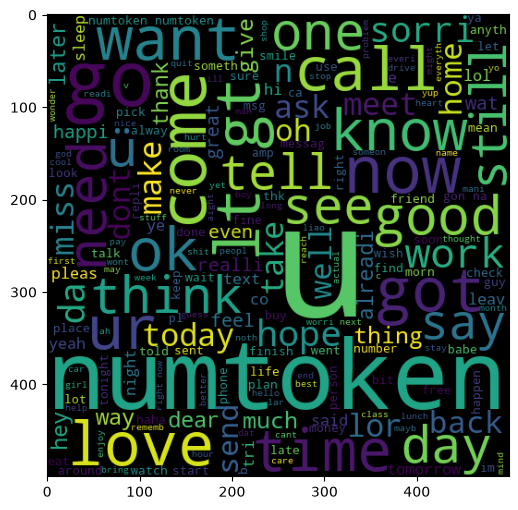

In [64]:
plt.figure(figsize=(15, 6))
plt.imshow(ham_wc)

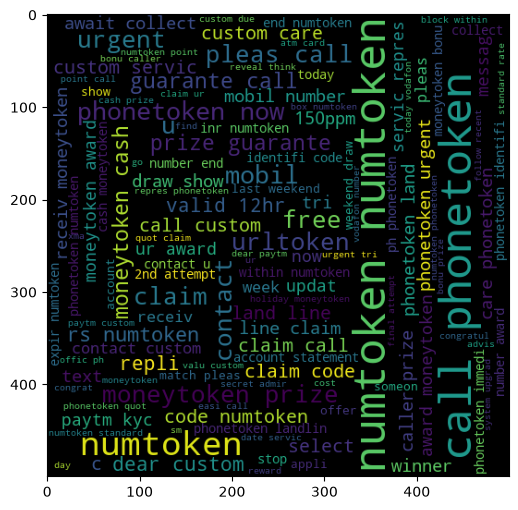

In [65]:
# now for smishing
smish = wc.generate(df[df["label"]==1]["transformed_text"].str.cat(sep=" "))
plt.figure(figsize=(15, 6))
plt.imshow(smish)

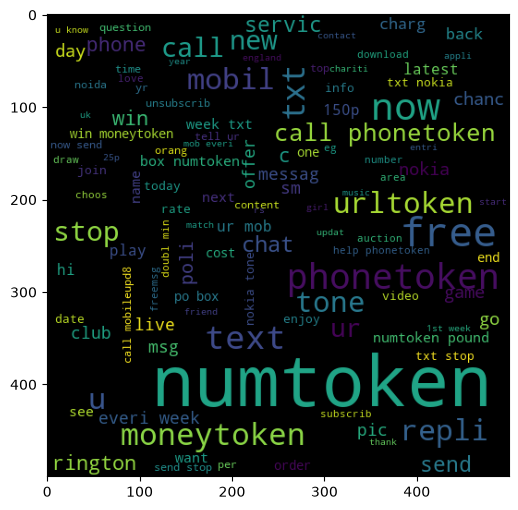

In [66]:
# now for spam
spam_wc = wc.generate(df[df["label"]==2]["transformed_text"].str.cat(sep=" "))
plt.figure(figsize=(15, 6))
plt.imshow(spam_wc)

#### now let view each word disribution in the graph

In [67]:
# create a corpu list for both spam and ham texts
# 1. for spam
spam_corpus = []
for msg in df[df["label"]==2]["transformed_text"].tolist() :
    for word in msg.split() :
        spam_corpus.append(word)

In [68]:
# 2. for ham
ham_corpus = []
for msg in df[df["label"]==0]["transformed_text"].tolist() :
    for word in msg.split() :
        ham_corpus.append(word)

In [69]:
# 2. for smishing
smish_corpus = []
for msg in df[df["label"]==1]["transformed_text"].tolist() :
    for word in msg.split() :
        smish_corpus.append(word)

In [70]:
# lets visualise now for spam_corpus

In [71]:
from collections import Counter
# its use : to count the frequency of elements in a list
# Counter(spam_corpus).most_common(30) #to see list

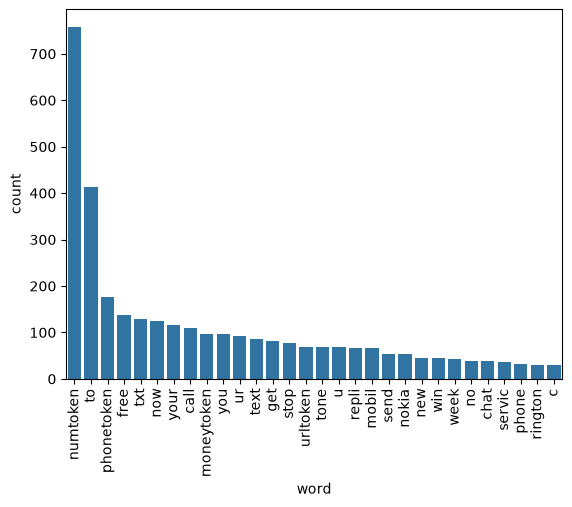

In [72]:
common_words = pd.DataFrame(
    Counter(spam_corpus).most_common(30),
    columns=["word", "count"]
)

sns.barplot(
    data=common_words,
    x="word",
    y="count"
)

plt.xticks(rotation="vertical")
plt.show()

### <span style="color:#7FB3D5">Phase-5: Model Building</span>

In [73]:
# here before moving forward now we need countvectorizer class to conver texts into binary table

#### <span style="color:#7FB3D5">Text Vectorization - CountVectorizer</span>

Machine Learning models cannot directly understand text data. Therefore, we need to convert the SMS text into **numerical values** before giving it to the ML model.

**CountVectorizer** is a technique used to convert text into a numerical matrix by **counting how many times each word appears in the text**.

#### Example:

Suppose we have two SMS messages:

| SMS | Text |
|---|---|
| SMS 1 | `you won a prize` |
| SMS 2 | `you won money` |

CountVectorizer first creates a **vocabulary** containing all unique words:

`a, money, prize, won, you`

It then represents each SMS using the frequency of these words:

| SMS | a | money | prize | won | you |
|---|---:|---:|---:|---:|---:|
| SMS 1 | 1 | 0 | 1 | 1 | 1 |
| SMS 2 | 0 | 1 | 0 | 1 | 1 |

Here, each number represents the **count of that word in the SMS**.

#### Why do we need CountVectorizer?

- ML models work with numerical data, not raw text.
- It converts text into a format that ML algorithms can understand.
- It creates a feature for each unique word.
- The value of each feature represents the frequency of that word.

#### Text Vectorization Flow

**Raw SMS → Text Preprocessing → CountVectorizer → Numerical Features → ML Model → Spam/Ham**

> **Note:** CountVectorizer is also known as the **Bag of Words (BoW)** approach because it represents text based on the words present and their frequency, without considering the order of the words.

In [74]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

y = df["label"].values

# split the dataframe (not a matrix), so you can still use the numeric columns later
train_df, test_df, y_train, y_test = train_test_split(
    df, y, test_size=0.2, stratify=y, random_state=42
)

cv = CountVectorizer()
X_train = cv.fit_transform(train_df["transformed_text"])   # learns vocabulary from train only
X_test  = cv.transform(test_df["transformed_text"])        # only converts, never learns

print(X_train.shape, X_test.shape)

(4631, 5919) (1158, 5919)


Now X now looks conceptually like this
| SMS   | call | free | money | prize | win |
| ----- | ---: | ---: | ----: | ----: | --: |
| SMS 1 |    0 |    1 |     1 |     0 |   1 |
| SMS 2 |    1 |    0 |     0 |     0 |   0 |
| SMS 3 |    0 |    2 |     0 |     1 |   1 |


In [76]:
X_train.shape
# 5169 rows → 5789 SMS messages
# 6708 columns → 6632 unique words/features created by CountVectorizer

(4631, 5919)

#### Train-Test Split

#### Using Naive Bayes classification algorithm.

In [77]:
# import
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, classification_report

In [78]:
# make objects
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

#### 1 -> mnb

In [79]:
mnb.fit(X_train, y_train)
y_pred_m = mnb.predict(X_test)

print("Accuracy of Multinomial Naive Bayes:", accuracy_score(y_test, y_pred_m))
print()
print(classification_report(y_test, y_pred_m, digits=3))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_m))

Accuracy of Multinomial Naive Bayes: 0.966321243523316

              precision    recall  f1-score   support

           0      0.988     0.995     0.991       966
           1      0.870     0.895     0.883       105
           2      0.831     0.736     0.780        87

    accuracy                          0.966      1158
   macro avg      0.896     0.875     0.885      1158
weighted avg      0.965     0.966     0.966      1158

Confusion Matrix:
[[961   2   3]
 [  1  94  10]
 [ 11  12  64]]


**Overall:** Accuracy is **96.6%**, and macro F1 is **0.885**. This is a good baseline for a plain Naive Bayes model.

## Per-Class Performance

| Class | Precision | Recall | F1-Score | Meaning |
|---|---:|---:|---:|---|
| 0 (Ham) | 0.988 | 0.995 | 0.991 | Almost perfect |
| 1 (Smishing) | 0.870 | 0.895 | 0.883 | Good |
| 2 (Spam) | 0.831 | 0.736 | 0.780 | Weakest class |

## Confusion Matrix Analysis

*Rows = true class, columns = predicted class.*

- **Ham:** 961 of 966 messages were classified correctly. Only 5 were misclassified (2 as Smishing and 3 as Spam).
- **Smishing:** 94 of 105 messages were classified correctly. Of the remaining 11, 10 were predicted as Spam and 1 as Ham.
- **Spam:** 64 of 87 messages were classified correctly. Of the remaining 23, 11 were predicted as Ham and 12 as Smishing.

## What to Notice

1. **Spam is the weakest class.** Its recall is **0.736**, meaning approximately 26.4% of actual Spam messages are missed. The 11 Spam messages classified as Ham are particularly important because they may pass through as legitimate messages.

2. **Smishing and Spam are frequently confused.** A total of **22 messages** are misclassified between these two classes (10 Smishing messages predicted as Spam and 12 Spam messages predicted as Smishing). This supports the earlier observation that both classes share similar characteristics, such as promotional language and urgency.

3. **Spam precision is 0.831.** Of all messages predicted as Spam, approximately 83.1% are genuinely Spam. The false positives include 3 Ham and 10 Smishing messages, indicating that confusion with Smishing accounts for most of these errors.

#### <span style="color:#F3C6D3">Precision in Imbalanced Data</span>

Since our dataset is **imbalanced**, accuracy alone may not give us a complete picture of model performance. Therefore, **precision is particularly important** for our spam classification problem because it tells us how many messages predicted as spam are actually spam.


#### 2 -> bnb

In [80]:
bnb.fit(X_train, y_train)
y_pred_b = bnb.predict(X_test)

print("Accuracy of Bernoulli Naive Bayes:", accuracy_score(y_test, y_pred_b))
print()
print(classification_report(y_test, y_pred_b, digits=3))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_b))

Accuracy of Bernoulli Naive Bayes: 0.9525043177892919

              precision    recall  f1-score   support

           0      0.956     1.000     0.978       966
           1      0.966     0.819     0.887       105
           2      0.864     0.586     0.699        87

    accuracy                          0.953      1158
   macro avg      0.929     0.802     0.854      1158
weighted avg      0.950     0.953     0.949      1158

Confusion Matrix:
[[966   0   0]
 [ 11  86   8]
 [ 33   3  51]]


#### 3 -> gnb

In [81]:
gnb.fit(X_train.toarray(), y_train)
y_pred_g = gnb.predict(X_test.toarray())

print("Accuracy of Gaussian Naive Bayes:", accuracy_score(y_test, y_pred_g))
print()
print(classification_report(y_test, y_pred_g, digits=3))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_g))

Accuracy of Gaussian Naive Bayes: 0.8367875647668394

              precision    recall  f1-score   support

           0      0.972     0.857     0.911       966
           1      0.503     0.829     0.626       105
           2      0.406     0.621     0.491        87

    accuracy                          0.837      1158
   macro avg      0.627     0.769     0.676      1158
weighted avg      0.887     0.837     0.853      1158

Confusion Matrix:
[[828  71  67]
 [  6  87  12]
 [ 18  15  54]]


In [82]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)

# each model with the input type it needs (Gaussian needs dense, others take sparse)
models = {
    "Multinomial NB": (mnb, X_test),
    "Bernoulli NB":   (bnb, X_test),
    "Gaussian NB":    (gnb, X_test.toarray()),   # convert once
}

results = []
for name, (model, X_eval) in models.items():
    y_pred = model.predict(X_eval)

    # per-class scores in order 0, 1, 2
    prec = precision_score(y_test, y_pred, average=None, zero_division=0)
    rec  = recall_score(y_test, y_pred, average=None, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Smishing Precision": prec[1],
        "Smishing Recall": rec[1],
        "Spam Precision": prec[2],
        "Spam Recall": rec[2],
    })

results_df = (pd.DataFrame(results)
                .set_index("Model")
                .round(3)
                .sort_values("Macro F1", ascending=False))

results_df

,Accuracy,Macro F1,Smishing Precision,Smishing Recall,Spam Precision,Spam Recall
Model,,,,,,
Multinomial NB,0.966,0.885,0.870,0.895,0.831,0.736
Bernoulli NB,0.953,0.854,0.966,0.819,0.864,0.586
Gaussian NB,0.837,0.676,0.503,0.829,0.406,0.621


#### <span style="color:#6FA8DC">Using **TF-IDF Now**</span>

**TF-IDF (Term Frequency–Inverse Document Frequency)** is a technique used to convert text into **numerical values** based on how important a word is in a particular document compared to the entire dataset.

It considers two things:

- **TF (Term Frequency)** → How frequently a word appears in a particular SMS.
- **IDF (Inverse Document Frequency)** → How rare or common that word is across all SMS messages.

Therefore:

- **Common words** → Lower importance
- **Rare and useful words** → Higher importance
- **Words that appear frequently in one SMS but rarely across the dataset** → Higher importance

For example, a word like **"you"** may appear in many SMS messages, so it receives a lower TF-IDF value. A word like **"prize"**, if it appears mainly in certain messages, may receive a higher value.

### TF-IDF Flow

**SMS Text → Preprocessing → TF-IDF Vectorizer → Numerical Features → ML Model**

In [111]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_text = df["transformed_text"].fillna("")
y = df["label"]

# Split the text BEFORE fitting TF-IDF
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=3000)

# Learn vocabulary and IDF weights from training text only
X_train = tfidf_vectorizer.fit_transform(X_train_text)

# Transform test text using the already learned vocabulary and IDF weights
X_test = tfidf_vectorizer.transform(X_test_text)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (4631, 3000)
Testing shape: (1158, 3000)


In [112]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [114]:
# Gaussian NB
gnb.fit(X_train.toarray(), y_train)
gnb_predic1 = gnb.predict(X_test.toarray())

# Multinomial NB
mnb.fit(X_train, y_train)
mnb_predic2 = mnb.predict(X_test)

# Bernoulli NB
bnb.fit(X_train, y_train)
bnb_predic3 = bnb.predict(X_test)

In [115]:
results = []

models = {
    "Gaussian Naive Bayes": gnb_predic1,
    "Multinomial Naive Bayes": mnb_predic2,
    "Bernoulli Naive Bayes": bnb_predic3
}

for name, y_pred in models.items():

    prec = precision_score(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Ham Precision": prec[0],
        "Phishing Precision": prec[1],
        "Spam Precision": prec[2]
    })

results_df = (
    pd.DataFrame(results)
    .set_index("Model")
    .round(3)
    .sort_values("Accuracy", ascending=False)
)

results_df

,Accuracy,Ham Precision,Phishing Precision,Spam Precision
Model,,,,
Bernoulli Naive Bayes,0.965,0.973,0.958,0.859
Multinomial Naive Bayes,0.944,0.949,0.917,0.886
Gaussian Naive Bayes,0.819,0.967,0.489,0.368


<br/>

### Experimenting more on diff models
<br/>

In [88]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\devma\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


### Cross Validation

### Why we are gonna use Stratified 5-Fold Cross-Validation now :

#### 1. What is Cross-Validation?

Cross-validation is a model evaluation technique used to estimate how well a machine learning model will perform on unseen data. Instead of evaluating a model using only one train-validation split, the training dataset is divided into multiple folds, and the model is trained and evaluated repeatedly.

In **5-fold cross-validation**, the dataset is divided into five approximately equal parts called folds.

- In each iteration, four folds are used for training.
- The remaining fold is used for validation.
- This process is repeated five times, so every fold is used for validation exactly once.
- The final performance is calculated by averaging the scores obtained across all five iterations.

#### 2. Why Do We Use StratifiedKFold?

Our ScamLens dataset contains three classes: Ham, Smishing, and Spam. These classes are imbalanced, meaning that the number of samples belonging to each class is not equal.

**StratifiedKFold** maintains approximately the same class proportions in every fold as in the original dataset.

For example, if the dataset contains 80% Ham, 12% Smishing, and 8% Spam messages, each fold will try to preserve these proportions.

#### Why is this important?

- It prevents validation folds from having drastically different class distributions.
- It helps ensure that minority classes, such as Smishing and Spam, are represented in every fold.
- It provides a more reliable comparison between different machine learning algorithms.
- It reduces dependence on a single train-validation split.

**Note:** StratifiedKFold preserves class proportions; it does not remove or correct the underlying class imbalance.

#### 3. Why Not Use a Single Train-Validation Split?

A model's performance can vary depending on which samples are included in the training and validation sets.

If a single split is used, the evaluation results may be influenced by that particular split.

Five-fold cross-validation evaluates the model across five different splits, providing a more representative estimate of its performance and stability.

#### 4. Why Do We Use Multiple Evaluation Metrics?

Accuracy alone can be misleading for imbalanced datasets.

For example, if 80% of the messages belong to the Ham class, a model that predicts every message as Ham can achieve 80% accuracy while failing to detect any Smishing or Spam messages.

Therefore, ScamLens uses the following metrics:

- **Accuracy:** Overall proportion of correctly classified messages.
- **Macro F1-score:** Calculates the F1-score for each class and gives every class equal weight.
- **Smishing precision:** Of the messages predicted as Smishing, the proportion that are actually Smishing.
- **Smishing recall:** Of the actual Smishing messages, the proportion correctly detected.
- **Spam precision:** Of the messages predicted as Spam, the proportion that are actually Spam.
- **Spam recall:** Of the actual Spam messages, the proportion correctly detected.
- **Spam F1-score:** Harmonic mean of Spam precision and Spam recall.

These metrics help us evaluate both overall classification performance and the model's ability to identify minority scam classes.

#### 5. Why Do We Calculate Mean and Standard Deviation?

Cross-validation produces five scores for each metric, one from each validation fold.

- **Mean score:** Represents the average performance across the five folds.
- **Standard deviation:** Measures how much the scores vary across the folds.

A higher mean score generally indicates better performance, while a lower standard deviation suggests more consistent performance across different splits.

#### 6. Why Do We Compare Multiple Algorithms?

In ScamLens, we use cross-validation to compare different machine learning algorithms under the same evaluation setup.

The results are sorted by mean macro F1-score to identify promising models. Smishing and Spam precision and recall are also examined because detecting scam messages is a key objective of the project.

The model with the highest macro F1-score is not automatically the best choice; its minority-class performance and false-positive behaviour must also be considered.

#### 7. Why Is a Separate Test Set Still Required?

Cross-validation is performed on the training data to compare candidate models. A separate test set is kept untouched during model selection.

After selecting and training the final model, we evaluate it on the held-out test set to estimate its performance on unseen messages.

This separation helps prevent overly optimistic evaluation results caused by repeatedly using the test set during model selection.

#### Conclusion

Stratified 5-fold cross-validation is used in ScamLens to compare machine learning algorithms more reliably on an imbalanced, multiclass SMS dataset. By preserving class proportions across folds and evaluating macro F1, Smishing precision and recall, and Spam precision and recall, we obtain a more informative assessment than accuracy or a single validation split alone.

In [116]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

In [103]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier




In [117]:
# Making objects (random_state added so results are repeatable)

lr  = LogisticRegression(max_iter=2000, class_weight="balanced")
svc = SVC(kernel="linear", class_weight="balanced")
dt  = DecisionTreeClassifier(class_weight="balanced", random_state=2)
rf  = RandomForestClassifier(class_weight="balanced", random_state=2)
etc = ExtraTreesClassifier(class_weight="balanced", random_state=2)

In [118]:

clfs = {
    "Logistic Regression": lr,
    "SVM": svc,
    "Multinomial Naive Bayes": mnb,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Extra Trees": etc,
}

In [119]:

from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

# Keep your existing class-specific metrics
scoring = {
    "macro_f1": "f1_macro",
    "smishing_recall": make_scorer(
        recall_score, labels=[1], average="macro", zero_division=0
    ),
    "smishing_precision": make_scorer(
        precision_score, labels=[1], average="macro", zero_division=0
    ),
    "spam_recall": make_scorer(
        recall_score, labels=[2], average="macro", zero_division=0
    ),
    "spam_precision": make_scorer(
        precision_score, labels=[2], average="macro", zero_division=0
    ),
    "spam_f1": make_scorer(
        f1_score, labels=[2], average="macro", zero_division=0
    ),
}

# Five-fold stratified cross-validation
cv_splitter = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

# IMPORTANT: use the raw processed training text, not X_train
X_cv_text = X_train_text

rows = []

for name, clf in clfs.items():

    # TF-IDF is refitted separately within each fold
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=3000)),
        ("classifier", clf)
    ])

    res = cross_validate(
        pipeline,
        X_cv_text,
        y_train,
        cv=cv_splitter,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Algorithm": name}

    for metric in scoring:
        row[metric] = res[f"test_{metric}"].mean()

    row["macro_f1_std"] = res["test_macro_f1"].std()
    row["spam_recall_std"] = res["test_spam_recall"].std()

    rows.append(row)

    print(
        f"{name}: macro F1 {row['macro_f1']:.3f} "
        f"± {row['macro_f1_std']:.3f}, "
        f"spam recall {row['spam_recall']:.3f} "
        f"± {row['spam_recall_std']:.3f}"
    )

performance_df = (
    pd.DataFrame(rows)
    .round(3)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(performance_df)


Logistic Regression: macro F1 0.884 ± 0.027, spam recall 0.815 ± 0.077
SVM: macro F1 0.898 ± 0.032, spam recall 0.798 ± 0.081
Multinomial Naive Bayes: macro F1 0.803 ± 0.011, spam recall 0.405 ± 0.019
Decision Tree: macro F1 0.825 ± 0.027, spam recall 0.705 ± 0.073
Random Forest: macro F1 0.911 ± 0.017, spam recall 0.774 ± 0.050
Extra Trees: macro F1 0.886 ± 0.017, spam recall 0.670 ± 0.050


,Algorithm,macro_f1,smishing_recall,smishing_precision,spam_recall,spam_precision,spam_f1,macro_f1_std,spam_recall_std
0,Random Forest,0.911,0.896,0.932,0.774,0.896,0.829,0.017,0.050
1,SVM,0.898,0.891,0.911,0.798,0.811,0.803,0.032,0.081
2,Extra Trees,0.886,0.884,0.933,0.670,0.894,0.765,0.017,0.050
3,Logistic Regression,0.884,0.886,0.909,0.815,0.730,0.769,0.027,0.077
4,Decision Tree,0.825,0.825,0.846,0.705,0.635,0.665,0.027,0.073
5,Multinomial Naive Bayes,0.803,0.851,0.884,0.405,0.960,0.569,0.011,0.019


In [129]:

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

# Final models selected from cross-validation
finalists = {
    "SVM": svc,
    "Logistic Regression": lr
}

final_pipelines = {}

for name, clf in finalists.items():

    # Combine TF-IDF and the classifier
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=3000)),
        ("classifier", clf)
    ])

    # Train using raw processed text
    pipeline.fit(X_train_text, y_train)

    # Predict on the untouched test text
    y_pred = pipeline.predict(X_test_text)

    final_pipelines[name] = pipeline

    print(f"\n=== {name} ===")

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=["ham", "smishing", "spam"],
        digits=3,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1, 2]))


c:\Users\devma\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



=== SVM ===
              precision    recall  f1-score   support

         ham      0.984     0.997     0.990       966
    smishing      0.938     0.867     0.901       105
        spam      0.805     0.759     0.781        87

    accuracy                          0.967      1158
   macro avg      0.909     0.874     0.891      1158
weighted avg      0.966     0.967     0.966      1158

Confusion Matrix:
[[963   0   3]
 [  1  91  13]
 [ 15   6  66]]

=== Logistic Regression ===
              precision    recall  f1-score   support

         ham      0.988     0.981     0.984       966
    smishing      0.907     0.838     0.871       105
        spam      0.683     0.793     0.734        87

    accuracy                          0.954      1158
   macro avg      0.859     0.871     0.863      1158
weighted avg      0.957     0.954     0.955      1158

Confusion Matrix:
[[948   1  17]
 [  2  88  15]
 [ 10   8  69]]


In [130]:
performance_df.sort_values('spam_precision', ascending=False)

,Algorithm,macro_f1,smishing_recall,smishing_precision,spam_recall,spam_precision,spam_f1,macro_f1_std,spam_recall_std
5,Multinomial Naive Bayes,0.803,0.851,0.884,0.405,0.960,0.569,0.011,0.019
0,Random Forest,0.911,0.896,0.932,0.774,0.896,0.829,0.017,0.050
2,Extra Trees,0.886,0.884,0.933,0.670,0.894,0.765,0.017,0.050
1,SVM,0.898,0.891,0.911,0.798,0.811,0.803,0.032,0.081
3,Logistic Regression,0.884,0.886,0.909,0.815,0.730,0.769,0.027,0.077
4,Decision Tree,0.825,0.825,0.846,0.705,0.635,0.665,0.027,0.073


In [131]:
performance_df1 = pd.melt(performance_df, id_vars="Algorithm")
# eep Algorithm as the identifier, and turn all the other columns into two columns: variable and value.

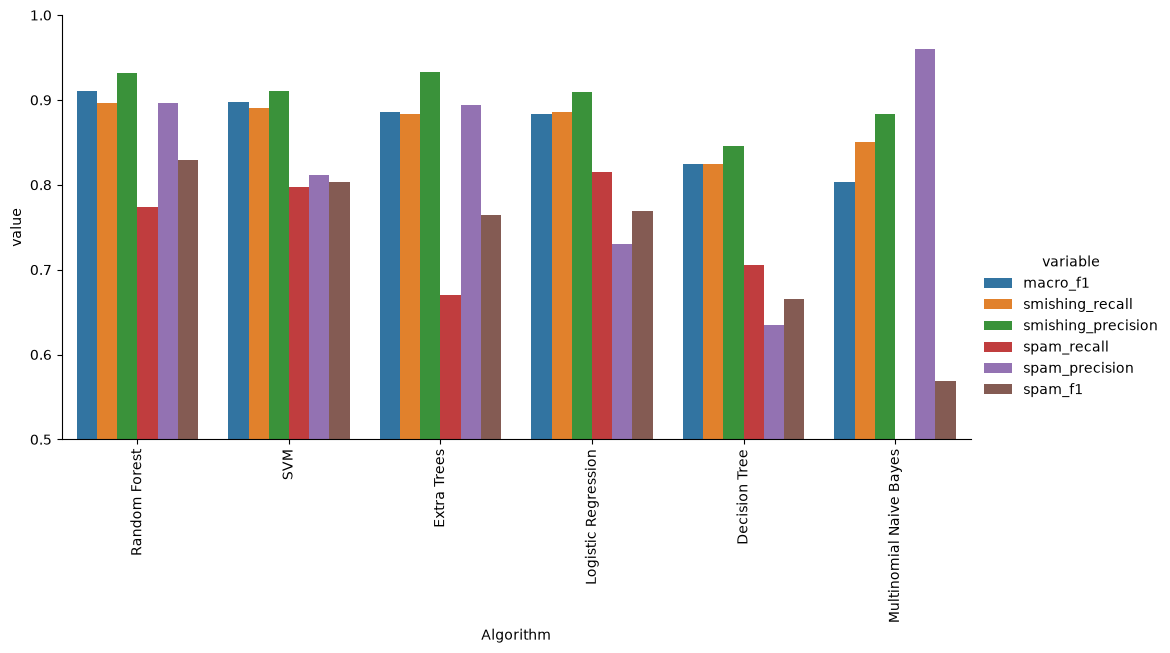

In [132]:
# keep Algorithm as the identifier, turn the chosen metric columns into variable/value
plot_cols = ["Algorithm", "macro_f1", "smishing_recall", "smishing_precision", "spam_recall", "spam_precision", "spam_f1"]
performance_df1 = pd.melt(performance_df[plot_cols], id_vars="Algorithm")

sns.catplot(
    x="Algorithm",
    y="value",
    hue="variable",
    data=performance_df1,
    kind="bar",
    height=5,
    aspect=2
)

plt.ylim(0.5, 1.0)
plt.xticks(rotation="vertical")
plt.show()

1. trying voting classifier to see results 

In [134]:

# Voting Classifier
from sklearn.ensemble import VotingClassifier, ExtraTreesClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

# SVM specifically for the voting experiment
voting_svc = SVC(
    kernel="sigmoid",
    gamma=1.0,
    probability=True,
    random_state=42
)

voting_nb = MultinomialNB()

voting_et = ExtraTreesClassifier(
    n_estimators=50,
    random_state=42
)

# Define the ensemble
voting = VotingClassifier(
    estimators=[
        ("svm", voting_svc),
        ("nb", voting_nb),
        ("et", voting_et)
    ],
    voting="soft"
)

# Combine TF-IDF and the Voting Classifier
voting_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=3000)),
    ("classifier", voting)
])

# Train on raw processed training text
voting_pipeline.fit(X_train_text, y_train)


c:\Users\devma\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",3000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


In [135]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predictions
y_pred = voting_pipeline.predict(X_test_text)

# 1. Overall evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

print("=" * 55)
print("       VOTING CLASSIFIER - EVALUATION METRICS")
print("=" * 55)

print(f"\nAccuracy          : {accuracy:.4f} ({accuracy * 100:.2f}%)")

for avg in ["macro", "weighted", "micro"]:
    print(f"\n{avg.upper()} AVERAGE")
    print("-" * 35)
    print(f"Precision         : {precision_score(y_test, y_pred, average=avg, zero_division=0):.4f}")
    print(f"Recall            : {recall_score(y_test, y_pred, average=avg, zero_division=0):.4f}")
    print(f"F1-Score          : {f1_score(y_test, y_pred, average=avg, zero_division=0):.4f}")

# 2. Separate metrics for each class
print("\n" + "=" * 55)
print("             CLASS-WISE METRICS")
print("=" * 55)

print(classification_report(
    y_test,
    y_pred,
    labels=range(len(encoder.classes_)),
    target_names=encoder.classes_,
    digits=4,
    zero_division=0
))

# 3. Store all metrics in a DataFrame
class_precision = precision_score(
    y_test, y_pred, average=None, labels=range(len(encoder.classes_)),
    zero_division=0
)
class_recall = recall_score(
    y_test, y_pred, average=None, labels=range(len(encoder.classes_)),
    zero_division=0
)
class_f1 = f1_score(
    y_test, y_pred, average=None, labels=range(len(encoder.classes_)),
    zero_division=0
)

class_metrics = pd.DataFrame({
    "Class": encoder.classes_,
    "Precision": class_precision,
    "Recall": class_recall,
    "F1-Score": class_f1
})

print("\nCLASS-WISE METRICS TABLE")
display(class_metrics.round(4))

# 4. Confusion matrix
cm = confusion_matrix(
    y_test, y_pred, labels=range(len(encoder.classes_))
)

confusion_df = pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in encoder.classes_],
    columns=[f"Predicted {c}" for c in encoder.classes_]
)

print("\nCONFUSION MATRIX")
display(confusion_df)


       VOTING CLASSIFIER - EVALUATION METRICS

Accuracy          : 0.9680 (96.80%)

MACRO AVERAGE
-----------------------------------
Precision         : 0.9205
Recall            : 0.8655
F1-Score          : 0.8902

WEIGHTED AVERAGE
-----------------------------------
Precision         : 0.9662
Recall            : 0.9680
F1-Score          : 0.9664

MICRO AVERAGE
-----------------------------------
Precision         : 0.9680
Recall            : 0.9680
F1-Score          : 0.9680

             CLASS-WISE METRICS
              precision    recall  f1-score   support

         ham     0.9807    1.0000    0.9903       966
    smishing     0.9216    0.8952    0.9082       105
        spam     0.8592    0.7011    0.7722        87

    accuracy                         0.9680      1158
   macro avg     0.9205    0.8655    0.8902      1158
weighted avg     0.9662    0.9680    0.9664      1158


CLASS-WISE METRICS TABLE


,Class,Precision,Recall,F1-Score
0,ham,0.9807,1.0000,0.9903
1,smishing,0.9216,0.8952,0.9082
2,spam,0.8592,0.7011,0.7722



CONFUSION MATRIX


,Predicted ham,Predicted smishing,Predicted spam
Actual ham,966,0,0
Actual smishing,1,94,10
Actual spam,18,8,61




#### 1. What I understood from Cross-Validation

I compared multiple ML models using Stratified 5-Fold Cross-Validation and focused mainly on Macro F1 and Spam Recall because my dataset is imbalanced.

- **Random Forest:** Best Macro F1 (0.892 ± 0.009).
- **SVM:** Macro F1 = 0.877 ± 0.006, Spam Recall = 0.761 ± 0.032.
- **Logistic Regression:** Macro F1 = 0.875 ± 0.012, Spam Recall = 0.775 ± 0.035.
- **Extra Trees:** Macro F1 = 0.874 ± 0.004, Spam Recall = 0.667 ± 0.037.

Random Forest has the highest average Macro F1, but the difference is relatively small. The variation across folds also matters, so I shouldn't select a model based on a tiny score difference alone.

I decided to drop KNN, AdaBoost, Decision Tree, Multinomial Naive Bayes, and Gradient Boosting because their results were less suitable for my Spam/Smishing detection goals.

#### 2. What I Learned from Test-Set Evaluation

SVM and Logistic Regression performed similarly on the test set.

| Metric | SVM | Logistic Regression |
|---|---:|---:|
| Macro F1 | 0.893 | 0.881 |
| Spam Recall | 0.780 | 0.756 |
| Spam Precision | 0.780 | 0.756 |
| Smishing Recall | 0.915 | 0.915 |
| Ham messages wrongly flagged | 11 | 15 |
| Total errors | 39 | 45 |

The difference is only 6 messages out of 1,158. I shouldn't conclude that SVM is definitively better based on this test set alone.

#### 3. Why I Chose Logistic Regression for ScamLens

My final model choice should depend on the product requirements, not just the highest score.

I want ScamLens to provide:
- Spam and Smishing detection.
- Prediction probabilities for the frontend.
- Per-message explanations showing which words contributed to a prediction.

Logistic Regression is a good fit because it provides probabilities and has interpretable feature coefficients, including word-level contributions when used with TF-IDF.

Random Forest performs well, but its global feature importances do not directly explain why a particular message received a prediction.

**Decision:** Use Logistic Regression as the initial production model, provided its probabilities and explanation outputs are validated for the final pipeline.

#### 4. What Class Weighting Changed

Using `class_weight="balanced"` helps the model account for underrepresented classes during training.

For ScamLens, the reported Spam Recall improved, but more legitimate Ham messages were incorrectly flagged.

I consider this trade-off reasonable because missing scam messages can be costly. However, I still need to monitor false positives so legitimate messages are not unnecessarily classified as suspicious.

#### 5. The Main Remaining Problem: Spam vs. Smishing

The confusion matrix shows overlap between the two suspicious classes:

- Spam → Ham: 9 messages.
- Spam → Smishing: 9 messages.
- Smishing → Spam: 9 messages.

The confusion between Spam and Smishing may mean that their message patterns overlap, or that some dataset labels are inconsistent.

My next step is to inspect the misclassified messages manually and check whether the errors come from similar wording, ambiguous categories, or incorrect labels.

#### Final Takeaway

I will prioritize a model that balances detection performance, false alarms, and explainability. Logistic Regression is my current choice for ScamLens because it fits the planned frontend explanations and probability outputs. I will validate the final model on held-out data and investigate the Spam–Smishing confusion before treating the model as production-ready.

## <span style="color:#90EE90">Next Phase : Model Serialization / Model Saving</span>

In [142]:
# Save the selected Logistic Regression pipeline.
# The notebook is responsible for training; the FastAPI backend only loads this file.
import pickle

final_model = final_pipelines["Logistic Regression"]
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

with MODEL_PATH.open("wb") as model_file:
    pickle.dump(final_model, model_file)

print(f"ScamLens Logistic Regression pipeline saved to: {MODEL_PATH.resolve()}")


ScamLens Logistic Regression pipeline saved.
